# Fase 2 · Parte 2: contrastes sobre variables numéricas (H2 y H4)

**Proyecto Integrador de Ciencia de Datos · Grupo 4**

**Responsable de esta parte:** Zinri Alice Bobadilla Peralta

Esta parte contrasta las dos hipótesis preliminares que involucran variables numéricas:

- **H2:** la edad de quienes reportaron enfermedad reciente difiere de la de quienes no.
- **H4:** existe asociación positiva entre años de estudio e ingreso per cápita mensual.

En ambos casos la prueba paramétrica (t de Student, correlación de Pearson) exige normalidad, por lo que la verificación de supuestos decide qué prueba se ejecuta. El marco común (α = 0,05, regla de decisión, corrección de Bonferroni) está declarado en la Parte 1.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.fase2 import datos, efectos, remuestreo, supuestos

pd.set_option("display.float_format", lambda v: f"{v:.3e}" if 0 < abs(v) < 1e-4 else f"{v:,.4f}")
datos.aplicar_estilo()

df = datos.cargar_datos()
registro = datos.RegistroContrastes(parte=2)

## 1. H2: edad y enfermedad reciente

- **H0:** P(edad_enf > edad_sano) = 0,5. Al tomar al azar una persona enferma y una sana, ninguna de las dos tiende a ser mayor que la otra.
- **H1:** P(edad_enf > edad_sano) ≠ 0,5. Uno de los grupos tiende a tener más edad (bilateral, α = 0,05).

**Selección de la prueba.** Se compara una variable numérica (edad, en años) entre dos grupos independientes (enfermo/a y sano/a). La prueba paramétrica es la **t de Student para muestras independientes**, que exige normalidad en cada grupo y varianzas homogéneas. Su alternativa no paramétrica es la **U de Mann-Whitney**. La hipótesis está escrita en la forma que contrasta Mann-Whitney porque la Fase 1 la enunció sobre la distribución de la edad y no sobre su media; si los supuestos de la t se cumplieran, se contrastaría la igualdad de medias.

### 1.1 Verificación de supuestos

In [2]:
edad_enf = df.loc[df["enfermedad_reciente"] == 1, "edad"]
edad_sano = df.loc[df["enfermedad_reciente"] == 0, "edad"]

descriptivos_h2 = pd.DataFrame({
    "Enfermo/a": edad_enf.describe(percentiles=[0.25, 0.5, 0.75]),
    "Sano/a": edad_sano.describe(percentiles=[0.25, 0.5, 0.75]),
}).T.rename(columns={"count": "n", "mean": "media", "std": "desvío", "50%": "mediana"})
display(descriptivos_h2.round(2))

print("Normalidad (Shapiro-Wilk sobre submuestra aleatoria de 5.000 casos por grupo)")
normalidad_h2 = supuestos.tabla_normalidad({"Enfermo/a": edad_enf, "Sano/a": edad_sano}, datos.ALFA)
display(normalidad_h2)

levene_h2 = supuestos.prueba_levene(edad_enf, edad_sano)
print(f"Levene (centrado en la mediana): W = {levene_h2['W']:.1f}; gl = ({levene_h2['gl1']}, {levene_h2['gl2']}); "
      f"p = {levene_h2['p']:.2e}; razón de varianzas = {levene_h2['razon_varianzas']:.2f}")

,n,media,desvío,min,25%,mediana,75%,max
Enfermo/a,"17,162.0000",35.3500,24.4700,0.0000,12.0000,33.0000,56.0000,102.0000
Sano/a,"39,947.0000",31.9200,20.6500,0.0000,15.0000,29.0000,46.0000,106.0000


Normalidad (Shapiro-Wilk sobre submuestra aleatoria de 5.000 casos por grupo)


,n,n_shapiro,W,p,asimetria,curtosis_exceso,normalidad
muestra,,,,,,,
Enfermo/a,17162,5000,0.9476,5.740e-39,0.2953,-1.0763,se rechaza
Sano/a,39947,5000,0.9606,8.224e-35,0.5113,-0.5022,se rechaza


Levene (centrado en la mediana): W = 1356.0; gl = (1, 57107); p = 2.18e-293; razón de varianzas = 1.41


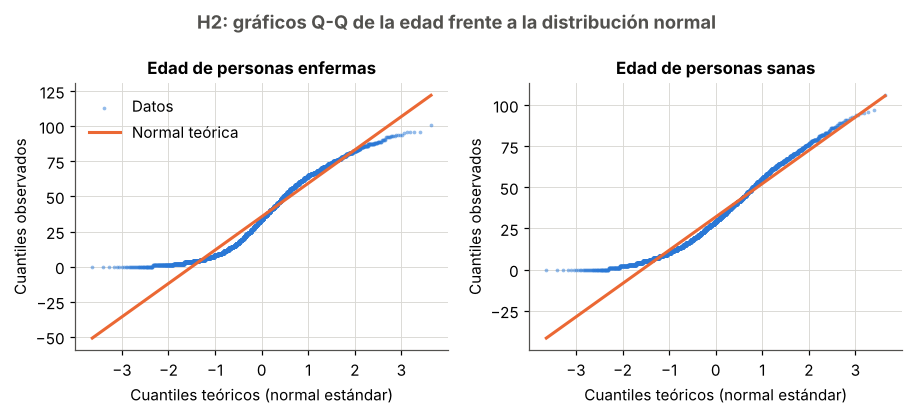

In [3]:
fig = supuestos.grafico_qq({"Edad de personas enfermas": edad_enf, "Edad de personas sanas": edad_sano},
                           "H2: gráficos Q-Q de la edad frente a la distribución normal")
datos.guardar_figura(fig, "f2_03_h2_qq_edad.png")
plt.show()

**Interpretación del gráfico.** Si la edad fuera normal, los puntos seguirían la recta. En ambos grupos se apartan en los extremos: la edad no puede ser negativa, así que la cola izquierda queda cortada en cero, y la cola derecha es más corta que la de una normal. En el grupo enfermo la curvatura es mayor porque hay muchos niños pequeños y muchos adultos mayores.

| Supuesto de la t de Student | Verificación | Resultado |
|---|---|---|
| Normalidad de la edad en cada grupo | Shapiro-Wilk: W = 0,948 y 0,961; p < 0,001 en ambos. Gráficos Q-Q con desvíos en las dos colas. Curtosis de −1,08 y −0,50 | **No se cumple** |
| Homogeneidad de varianzas | Levene: W = 1.356; p < 0,001. La varianza del grupo enfermo es 1,41 veces la del sano | **No se cumple** |
| Independencia de las observaciones | ICC por hogar 0,31 (Parte 1) | **No se cumple** |

**Decisión:** se descarta la t de Student y se aplica la **U de Mann-Whitney**, que no requiere normalidad. Su valor p clásico supone que, bajo H0, las dos distribuciones tienen la misma forma, algo que tampoco se cumple del todo (razón de varianzas 1,41), y además supone independencia. Por eso la decisión se apoya en la versión robusta: el error estándar de la probabilidad de superioridad se estima por bootstrap de conglomerados (UPM), que no necesita ninguno de esos dos supuestos.

Una aclaración: con más de 17.000 casos por grupo, la media muestral es aproximadamente normal por el teorema central del límite y la t de Welch también sería defendible para comparar medias. Se elige Mann-Whitney porque las formas de las dos distribuciones son distintas y la media no resume bien una distribución con dos concentraciones (niños y adultos mayores).

### 1.2 Ejecución de la prueba

In [4]:
n_enf, n_sano = len(edad_enf), len(edad_sano)
mw = stats.mannwhitneyu(edad_enf, edad_sano, alternative="two-sided", method="asymptotic")

# Estadístico z equivalente (aproximación normal de U con corrección por empates)
z_h2 = np.sign(mw.statistic - n_enf * n_sano / 2) * stats.norm.isf(mw.pvalue / 2)

# Tamaños del efecto
prob_sup = mw.statistic / (n_enf * n_sano)          # P(edad_enf > edad_sano), empates cuentan 1/2
r_biserial = efectos.biserial_rangos(prob_sup)
d_h2 = efectos.d_cohen(edad_enf, edad_sano)
magnitud_h2 = efectos.magnitud(r_biserial, "r")


# Versión robusta: bootstrap por UPM de la probabilidad de superioridad y de la diferencia de medianas
def prob_superioridad_grupos(edad, enfermo):
    return efectos.probabilidad_superioridad(edad[enfermo == 1], edad[enfermo == 0])


def diferencia_medianas(edad, enfermo):
    return np.median(edad[enfermo == 1]) - np.median(edad[enfermo == 0])


edad, enfermo = df["edad"].to_numpy(), df["enfermedad_reciente"].to_numpy()
boot_ps = remuestreo.ic_bootstrap(prob_superioridad_grupos, edad, enfermo, conglomerados=df["UPM"])
boot_med = remuestreo.ic_bootstrap(diferencia_medianas, edad, enfermo, conglomerados=df["UPM"])
z_rob_h2, p_rob_h2 = remuestreo.p_desde_error_estandar(boot_ps["estimacion"], boot_ps["error_estandar"], valor_nulo=0.5)

pd.Series({
    "U de Mann-Whitney": mw.statistic,
    "z equivalente": z_h2,
    "Valor p clásico": mw.pvalue,
    "Probabilidad de superioridad P(enf > sano)": prob_sup,
    "  IC 95 % de P, inferior (bootstrap por UPM)": boot_ps["inf"],
    "  IC 95 % de P, superior (bootstrap por UPM)": boot_ps["sup"],
    "z robusto (EE bootstrap por UPM)": z_rob_h2,
    "Valor p robusto": p_rob_h2,
    "Correlación biserial por rangos": r_biserial,
    "d de Cohen (referencia)": d_h2,
    "Diferencia de medianas, en años": boot_med["estimacion"],
    "  IC 95 % de la diferencia, inferior (bootstrap por UPM)": boot_med["inf"],
    "  IC 95 % de la diferencia, superior (bootstrap por UPM)": boot_med["sup"],
}, name="H2").to_frame()

,H2
U de Mann-Whitney,"364,551,071.0000"
z equivalente,12.0511
Valor p clásico,1.913e-33
Probabilidad de superioridad P(enf > sano),0.5317
"IC 95 % de P, inferior (bootstrap por UPM)",0.5256
"IC 95 % de P, superior (bootstrap por UPM)",0.5381
z robusto (EE bootstrap por UPM),9.6972
Valor p robusto,3.100e-22
Correlación biserial por rangos,0.0635
d de Cohen (referencia),0.1570


In [5]:
registro.agregar(
    id="H2",
    hipotesis="La edad difiere entre personas con y sin enfermedad reciente",
    variables="edad × enfermedad_reciente",
    familia="Comparar dos grupos independientes",
    prueba="U de Mann-Whitney",
    supuestos="Normalidad: no cumple (Shapiro-Wilk, Q-Q). Varianzas: no cumple (Levene). Se descarta t de Student",
    n=n_enf + n_sano,
    estadistico="z", valor_estadistico=z_h2, gl=np.nan,
    p_clasico=mw.pvalue, p_robusto=p_rob_h2,
    efecto="r biserial por rangos", valor_efecto=r_biserial, magnitud=magnitud_h2,
    ic_parametro="P(edad enfermo > edad sano)",
    ic_inf=boot_ps["inf"], ic_sup=boot_ps["sup"], ic_metodo="bootstrap por UPM",
)

### 1.3 La relación entre edad y enfermedad no es lineal

Mann-Whitney responde si un grupo tiende a tener más edad que el otro. Antes de interpretar el resultado conviene mirar cómo cambia la proporción de enfermedad a lo largo de la vida.

,prevalencia,inf,sup,n
0-4,38.4600,36.7600,40.0700,"4,241.0000"
5-14,31.1500,29.9300,32.2900,"10,303.0000"
15-29,22.1300,21.2900,23.0000,"13,359.0000"
30-44,25.1000,24.1600,26.0200,"12,229.0000"
45-59,31.0400,29.9900,32.2200,"8,564.0000"
60+,43.2400,42.0200,44.4800,"8,413.0000"


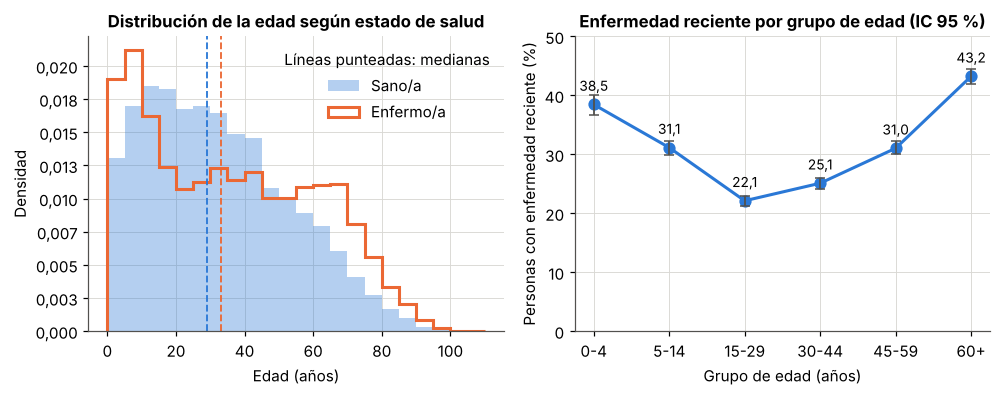

In [6]:
def prevalencia_ic(mascara):
    r = remuestreo.ic_bootstrap(np.mean, enfermo[mascara], conglomerados=df.loc[mascara, "UPM"], n_rep=1000)
    return {"prevalencia": r["estimacion"] * 100, "inf": r["inf"] * 100, "sup": r["sup"] * 100, "n": int(mascara.sum())}


prev_edad = pd.DataFrame({g: prevalencia_ic((df["grupo_edad"] == g).to_numpy()) for g in datos.ETIQUETAS_EDAD}).T
display(prev_edad.round(2))

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(9.2, 3.7))
cortes = np.arange(0, 111, 5)
eje1.hist(edad_sano, bins=cortes, density=True, histtype="stepfilled", color=datos.AZUL, alpha=0.35, label="Sano/a")
eje1.hist(edad_enf, bins=cortes, density=True, histtype="step", color=datos.NARANJA, linewidth=2, label="Enfermo/a")
eje1.axvline(edad_sano.median(), color=datos.AZUL, linestyle="--", linewidth=1.2)
eje1.axvline(edad_enf.median(), color=datos.NARANJA, linestyle="--", linewidth=1.2)
eje1.set_xlabel("Edad (años)")
eje1.set_ylabel("Densidad")
datos.ejes_con_coma(eje1, decimales_y=3)
eje1.set_title("Distribución de la edad según estado de salud")
eje1.legend(title="Líneas punteadas: medianas")

x = np.arange(len(prev_edad))
eje2.plot(x, prev_edad["prevalencia"], color=datos.AZUL, linewidth=2, marker="o", markersize=7)
eje2.errorbar(x, prev_edad["prevalencia"], yerr=[prev_edad["prevalencia"] - prev_edad["inf"], prev_edad["sup"] - prev_edad["prevalencia"]],
              fmt="none", color=datos.GRIS, capsize=3, linewidth=1.2)
for xi, v in zip(x, prev_edad["prevalencia"]):
    eje2.annotate(f"{v:.1f}".replace(".", ","), (xi, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
eje2.set_xticks(x, prev_edad.index)
eje2.set_ylim(0, 50)
eje2.set_xlabel("Grupo de edad (años)")
eje2.set_ylabel("Personas con enfermedad reciente (%)")
eje2.set_title("Enfermedad reciente por grupo de edad (IC 95 %)")
fig.tight_layout()
datos.guardar_figura(fig, "f2_04_h2_edad_enfermedad.png")
plt.show()

**Interpretación del gráfico.** A la izquierda, la distribución de la edad de las personas enfermas (línea naranja) tiene más peso que la de las sanas en los dos extremos: menores de 5 años y mayores de 60. A la derecha se ve la consecuencia: la proporción de enfermedad tiene forma de U. Es alta en la primera infancia (38,5 %), baja hasta un mínimo entre los 15 y 29 años (22,1 %) y vuelve a subir hasta 43,2 % desde los 60 años.

**Resultado de H2.** La mediana de edad es 33 años entre las personas enfermas y 29 entre las sanas.

- **Análisis clásico:** U = 364.551.071; z = 12,05; p < 0,001.
- **Análisis robusto a conglomerados:** z = 9,70; p < 0,001. La probabilidad de que una persona enferma tomada al azar tenga más edad que una sana es 0,532, contando los empates como medio (IC 95 % por bootstrap: 0,526 a 0,538). La diferencia de medianas es de 4 años (IC 95 %: 3 a 5).
- **Tamaño del efecto:** correlación biserial por rangos = 0,06 (trivial). Como referencia, d de Cohen = 0,16.

**En lenguaje llano.** Las personas que enfermaron tienden a ser algo mayores, pero la superposición entre los dos grupos es casi total: si se elige al azar una persona enferma y una sana, la enferma es la mayor en alrededor del 53 % de los casos, apenas por encima del 50 % que daría una moneda.

**Significancia frente a relevancia.** El efecto resumido en un solo número es trivial, y sin embargo la edad es una de las variables más relacionadas con la enfermedad: la diferencia entre el grupo de 15 a 29 años y el de 60 o más es de 21 puntos porcentuales. La contradicción es aparente. Una prueba de dos grupos solo detecta desplazamientos en un sentido, y aquí los niños y los adultos mayores empujan en sentidos opuestos y se compensan. **La edad importa, pero no de forma lineal.** Por eso en H6 y en la Fase 3 la edad se usa en tramos.

**Posible variable de confusión.** El sexo: en la muestra las mujeres tienen algo más de edad en promedio (33,4 frente a 32,5 años) y también reportan más enfermedad (Fase 1), de modo que parte de la relación entre edad y enfermedad puede deberse a la composición por sexo. Además, la información de niños pequeños la reporta un adulto del hogar, lo que puede afectar de forma distinta el registro en ese tramo.

## 2. H4: años de estudio e ingreso per cápita

- **H0:** ρ ≤ 0. No hay asociación positiva entre años de estudio e ingreso per cápita mensual.
- **H1:** ρ > 0. A más años de estudio, mayor ingreso (unilateral, α = 0,05). La dirección ya estaba enunciada en la hipótesis preliminar 4 de la Fase 1.

**Población.** Personas de 25 años o más con ambos datos disponibles. Los niños y jóvenes todavía no completaron su educación: sus años de estudio dependen de la edad y no del nivel que alcanzarán (corrección 4 de la Parte 1).

**Selección de la prueba.** Son dos variables numéricas y se evalúa la significancia de una correlación. La prueba paramétrica es la de **r de Pearson**, que exige relación lineal, normalidad conjunta y ausencia de valores extremos influyentes. La alternativa es la prueba sobre **ρ de Spearman**, que solo exige una relación monótona.

### 2.1 Verificación de supuestos

In [7]:
adultos = df[df["edad"] >= datos.EDAD_MINIMA_EDUCACION].dropna(subset=["anios_estudio", "ingreso_per_capita_mensual"])
estudio = adultos["anios_estudio"].to_numpy()
ingreso = adultos["ingreso_per_capita_mensual"].to_numpy()

print(f"Personas de {datos.EDAD_MINIMA_EDUCACION} años o más: {(df['edad'] >= datos.EDAD_MINIMA_EDUCACION).sum():,} "
      f"| con ambos datos: {len(adultos):,} | hogares: {adultos['hogar_id'].nunique():,}")

normalidad_h4 = supuestos.tabla_normalidad({
    "Años de estudio": estudio,
    "Ingreso per cápita": ingreso,
    "log(1 + ingreso per cápita)": np.log1p(ingreso),
}, datos.ALFA)
display(normalidad_h4)

p99 = np.quantile(ingreso, 0.99)
print(f"Ingreso: mediana = {np.median(ingreso):,.0f} Gs.; percentil 99 = {p99:,.0f} Gs.; máximo = {ingreso.max():,.0f} Gs. "
      f"({ingreso.max() / np.median(ingreso):.0f} veces la mediana)")

Personas de 25 años o más: 33,573 | con ambos datos: 33,487 | hogares: 16,677


,n,n_shapiro,W,p,asimetria,curtosis_exceso,normalidad
muestra,,,,,,,
Años de estudio,33487,5000,0.9497,2.319e-38,0.0417,-1.1289,se rechaza
Ingreso per cápita,33487,5000,0.4549,5.002e-82,10.8988,258.5763,se rechaza
log(1 + ingreso per cápita),33487,5000,0.9584,1.355e-35,-0.2474,8.5668,se rechaza


Ingreso: mediana = 1,527,778 Gs.; percentil 99 = 12,869,584 Gs.; máximo = 146,786,737 Gs. (96 veces la mediana)


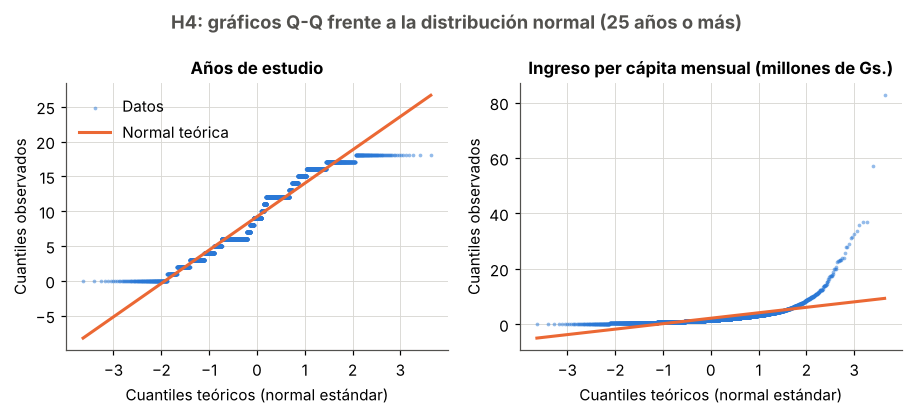

In [8]:
fig = supuestos.grafico_qq({"Años de estudio": estudio, "Ingreso per cápita mensual (millones de Gs.)": ingreso / 1e6},
                           "H4: gráficos Q-Q frente a la distribución normal (25 años o más)")
datos.guardar_figura(fig, "f2_05_h4_qq.png")
plt.show()

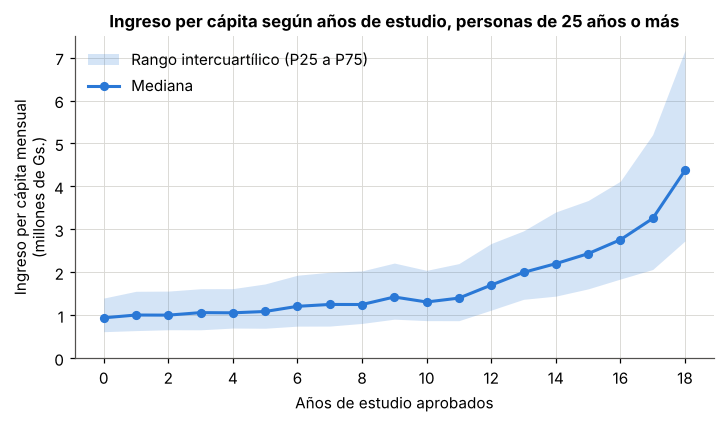

Casos por cantidad de años de estudio (mínimo): 557
Mediana de ingreso (millones de Gs.) con 0, 6, 12 y 16 años de estudio: {0.0: 0.94, 6.0: 1.21, 12.0: 1.7, 16.0: 2.76}
Pasos en los que la mediana baja al sumar un año de estudio (variación %): {2.0: -0.3, 4.0: -0.4, 8.0: -0.1, 10.0: -8.2}
Edad media por sexo: {'Hombre': 32.5, 'Mujer': 33.4}


In [9]:
# Linealidad: ingreso típico para cada cantidad de años de estudio
por_anio = adultos.groupby("anios_estudio")["ingreso_per_capita_mensual"].quantile([0.25, 0.5, 0.75]).unstack() / 1e6
conteo = adultos.groupby("anios_estudio").size()

fig, eje = plt.subplots(figsize=(7.5, 3.8))
eje.fill_between(por_anio.index, por_anio[0.25], por_anio[0.75], color=datos.AZUL, alpha=0.2, linewidth=0, label="Rango intercuartílico (P25 a P75)")
eje.plot(por_anio.index, por_anio[0.5], color=datos.AZUL, linewidth=2, marker="o", markersize=5, label="Mediana")
eje.set_xticks(range(0, 19, 2))
eje.set_ylim(0, None)
eje.set_xlabel("Años de estudio aprobados")
eje.set_ylabel("Ingreso per cápita mensual\n(millones de Gs.)")
eje.set_title("Ingreso per cápita según años de estudio, personas de 25 años o más")
eje.legend(loc="upper left")
datos.guardar_figura(fig, "f2_06_h4_ingreso_por_estudio.png")
plt.show()
print("Casos por cantidad de años de estudio (mínimo):", int(conteo.min()))
print("Mediana de ingreso (millones de Gs.) con 0, 6, 12 y 16 años de estudio:", por_anio.loc[[0, 6, 12, 16], 0.5].round(2).to_dict())
cambios = por_anio[0.5].pct_change().dropna() * 100
print("Pasos en los que la mediana baja al sumar un año de estudio (variación %):", cambios[cambios < 0].round(1).to_dict())
print("Edad media por sexo:", df.groupby("sexo")["edad"].mean().round(1).to_dict())

**Interpretación de los gráficos.** Los Q-Q muestran que ninguna de las dos variables es normal: los años de estudio forman escalones (es una variable discreta con concentraciones en 6, 12 y 16 años) y el ingreso tiene una cola derecha extrema. El gráfico de medianas muestra una relación **creciente pero no lineal**: la mediana del ingreso cambia poco entre 0 y 6 años de estudio (de 0,94 a 1,21 millones de Gs.) y se acelera a partir de los 12 (1,70 millones con 12 años; 2,76 millones con 16). La banda se ensancha con la educación, es decir, la dispersión no es constante.

| Supuesto de la prueba sobre r de Pearson | Verificación | Resultado |
|---|---|---|
| Normalidad de ambas variables | Shapiro-Wilk: p < 0,001 en las dos. Asimetría del ingreso = 10,9; curtosis = 259. Tampoco se logra con la transformación logarítmica (p < 0,001) | **No se cumple** |
| Relación lineal | La mediana del ingreso crece de forma convexa con los años de estudio | **No se cumple** |
| Sin valores extremos influyentes | El ingreso máximo es 96 veces la mediana | **No se cumple** |
| Relación monótona (supuesto de Spearman) | La mediana del ingreso crece con los años de estudio; las bajas son menores a 1 % salvo entre 9 y 10 años (8 %) | Se cumple de forma aproximada |
| Independencia de las observaciones | El ingreso per cápita es el mismo para todos los integrantes del hogar | **No se cumple** |

**Decisión:** se descarta la prueba de Pearson y se aplica la prueba sobre **ρ de Spearman**. La falta de independencia aquí es estructural (todos los adultos de un hogar comparten el mismo ingreso per cápita), así que el intervalo de confianza y el valor p robusto se obtienen por bootstrap de conglomerados (UPM).

### 2.2 Ejecución de la prueba

In [10]:
n_h4 = len(adultos)
sp = stats.spearmanr(estudio, ingreso, alternative="greater")
rho = sp.statistic
t_h4 = rho * np.sqrt((n_h4 - 2) / (1 - rho ** 2))          # estadístico t asociado a rho, con n-2 grados de libertad

ic_fisher = efectos.ic_correlacion_fisher(rho, n_h4, metodo="spearman")
boot_rho = remuestreo.ic_bootstrap(efectos.spearman_rapido, estudio, ingreso, conglomerados=adultos["UPM"])
z_rob_h4, p_rob_h4 = remuestreo.p_desde_error_estandar(boot_rho["estimacion"], boot_rho["error_estandar"], alternativa="mayor")
magnitud_h4 = efectos.magnitud(rho, "r")

# Referencias descriptivas (no son contrastes adicionales)
r_pearson = stats.pearsonr(estudio, ingreso).statistic
ic_pearson = efectos.ic_correlacion_fisher(r_pearson, n_h4, metodo="pearson")
todas = df.dropna(subset=["anios_estudio", "ingreso_per_capita_mensual"])
rho_todas = efectos.spearman_rapido(todas["anios_estudio"], todas["ingreso_per_capita_mensual"])

pd.Series({
    "n": n_h4,
    "rho de Spearman": rho,
    "t asociado (gl = n − 2)": t_h4,
    "Valor p clásico (unilateral)": max(sp.pvalue, 1e-300),      # menor a 1e-300: se muestra ese tope
    "IC 95 % clásico, inferior (Fisher)": ic_fisher[0],
    "IC 95 % clásico, superior (Fisher)": ic_fisher[1],
    "IC 95 % bootstrap por UPM, inferior": boot_rho["inf"],
    "IC 95 % bootstrap por UPM, superior": boot_rho["sup"],
    "z robusto (EE bootstrap por UPM)": z_rob_h4,
    "Valor p robusto (unilateral)": max(p_rob_h4, 1e-300),
    "rho al cuadrado": rho ** 2,
    "Referencia: r de Pearson": r_pearson,
    "Referencia: IC 95 % de r, inferior (Fisher)": ic_pearson[0],
    "Referencia: IC 95 % de r, superior (Fisher)": ic_pearson[1],
    "Referencia: rho con todas las edades": rho_todas,
}, name="H4").to_frame()

,H4
n,"33,487.0000"
rho de Spearman,0.4703
t asociado (gl = n − 2),97.5077
Valor p clásico (unilateral),1.000e-300
"IC 95 % clásico, inferior (Fisher)",0.4614
"IC 95 % clásico, superior (Fisher)",0.4790
"IC 95 % bootstrap por UPM, inferior",0.4568
"IC 95 % bootstrap por UPM, superior",0.4830
z robusto (EE bootstrap por UPM),68.1958
Valor p robusto (unilateral),1.000e-300


In [11]:
registro.agregar(
    id="H4",
    hipotesis="Asociación positiva entre años de estudio e ingreso per cápita (25 años o más)",
    variables="anios_estudio × ingreso_per_capita_mensual",
    familia="Significancia de una correlación",
    prueba="rho de Spearman (unilateral)",
    supuestos="Normalidad, linealidad y extremos: no cumplen, se descarta Pearson. Monotonía: cumple de forma aproximada",
    n=n_h4,
    estadistico="t", valor_estadistico=t_h4, gl=n_h4 - 2,
    p_clasico=sp.pvalue, p_robusto=p_rob_h4,
    efecto="rho de Spearman", valor_efecto=rho, magnitud=magnitud_h4,
    ic_parametro="rho de Spearman",
    ic_inf=boot_rho["inf"], ic_sup=boot_rho["sup"], ic_metodo="bootstrap por UPM",
)

**Resultado de H4.** En las 33.487 personas de 25 años o más, ρ de Spearman = 0,470.

- **Análisis clásico:** t = 97,5 con 33.485 grados de libertad; p < 0,001. IC 95 % por transformación de Fisher: 0,461 a 0,479.
- **Análisis robusto a conglomerados:** IC 95 % por bootstrap de UPM: 0,457 a 0,483; z = 68; p < 0,001. El intervalo robusto es cerca de 50 % más ancho que el clásico, porque los adultos de un mismo hogar repiten el mismo ingreso, pero queda muy lejos de cero.
- **Tamaño del efecto:** ρ = 0,47 es un efecto mediano, cercano al umbral de efecto grande (0,5). Es el contraste con el mayor efecto estandarizado de la fase.
- **Referencias:** r de Pearson = 0,281, bastante menor que ρ. La diferencia confirma que Pearson no era adecuado: los ingresos extremos y la curvatura atenúan la correlación lineal. Con todas las edades, ρ = 0,393 (el valor informado en la Fase 1); al restringir a adultos la asociación es más fuerte, lo que respalda la corrección.

**En lenguaje llano.** Entre los adultos, quienes estudiaron más años viven en hogares con mayor ingreso por persona. La relación es clara y no puede atribuirse al azar: la mediana de ingreso de quienes tienen 16 años de estudio (2,76 millones de Gs.) es más del doble de la de quienes tienen 6 (1,21 millones).

**Significancia frente a relevancia.** Aquí coinciden con claridad: el resultado es significativo y su efecto estandarizado es el mayor de la fase.

**Posible variable de confusión.** No se afirma que estudiar más cause mayor ingreso. La edad y la generación pueden relacionarse con ambas variables, igual que el área de residencia. Además el ingreso es del hogar y per cápita: depende de cuántas personas viven en él y de lo que ganan los demás integrantes, no solo de la educación de la persona.

**Relación con la pregunta de investigación.** H4 no trata sobre enfermedad, pero importa para la Fase 3: educación e ingreso están correlacionados entre sí, de modo que incluir ambos en un modelo aporta información parcialmente redundante.

In [12]:
ruta = registro.guardar()
print("Resultados guardados en:", ruta.relative_to(RAIZ))
registro.tabla()[["id", "prueba", "n", "valor_estadistico", "gl", "p_clasico", "p_robusto", "valor_efecto", "magnitud", "ic_inf", "ic_sup"]]

Resultados guardados en: output/fase2/contrastes_parte2.csv


,id,prueba,n,valor_estadistico,gl,p_clasico,p_robusto,valor_efecto,magnitud,ic_inf,ic_sup
0,H2,U de Mann-Whitney,57109,12.0511,NaN,1.913e-33,3.100e-22,0.0635,trivial,0.5256,0.5381
1,H4,rho de Spearman (unilateral),33487,97.5077,"33,485.0000",0.0000,0.0000,0.4703,mediano,0.4568,0.4830
